# NASA Kepler — Tuned Decision Tree Baseline



In [ ]:
from pathlib import Path
import io
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.model_selection import StratifiedGroupKFold, RandomizedSearchCV, cross_validate
from sklearn.metrics import (f1_score, precision_score, recall_score, accuracy_score, roc_auc_score, RocCurveDisplay,
                             classification_report, ConfusionMatrixDisplay)
import joblib

ZIP = Path("Kepler_Datasets")

from pathlib import Path
import pandas as pd


DATA_DIR = Path("Kepler_Datasets")


X_train = pd.read_csv(DATA_DIR / "X_train.csv")
y_train = pd.read_csv(DATA_DIR / "y_train.csv")["target"].astype(int)
train_ids = pd.read_csv(DATA_DIR / "train_ids.csv")


X_test = pd.read_csv(DATA_DIR / "X_test.csv")
y_test = pd.read_csv(DATA_DIR / "y_test.csv")["target"].astype(int)
test_ids = pd.read_csv(DATA_DIR / "test_ids.csv")

print("Datasets loaded successfully!")
print("Training shape:", X_train.shape)
print("Test shape:", X_test.shape)

assert len(X_train) == len(y_train) == len(train_ids)
assert X_train.shape[1] == 19
assert set(y_train.unique()) == {0, 1}
assert "kepid" in train_ids
assert not np.isinf(X_train.to_numpy(dtype=float)).any()
groups = train_ids["kepid"]
print("Training samples:", len(X_train))
print("Features:", len(X_train.columns))
print("Unique host stars:", groups.nunique())
print("Class distribution:", y_train.value_counts().to_dict())

Datasets loaded successfully!
Training shape: (7662, 19)
Test shape: (1902, 19)
Training samples: 7662
Features: 19
Unique host stars: 6571
Class distribution: {0: 3858, 1: 3804}


## 1. Untuned reference model


In [3]:
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"f1": "f1", "precision": "precision", "recall": "recall", "accuracy": "accuracy", "roc_auc": "roc_auc"}
reference = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("tree", DecisionTreeClassifier(random_state=42)),
])
reference_cv = cross_validate(reference, X_train, y_train,
                              groups=groups, cv=cv, scoring=scoring, n_jobs=-1)
reference_scores = {m: float(reference_cv[f"test_{m}"].mean()) for m in scoring}
print("Untuned Decision Tree (mean 5-fold group-aware CV):")
print(pd.Series(reference_scores).round(4))

Untuned Decision Tree (mean 5-fold group-aware CV):
f1           0.7795
precision    0.7800
recall       0.7792
accuracy     0.7813
roc_auc      0.7812
dtype: float64


## 2. Hyperparameter tuning
We tune **tree depth**, **minimum samples to split a node**, **minimum samples in a leaf**, **split criterion**, and **class weighting**. The search selects parameters by **mean validation F1-score**, not test-set performance.

In [4]:
pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("tree", DecisionTreeClassifier(random_state=42)),
])
param_distributions = {
    "tree__max_depth": [3, 5, 8, 12, 16, None],
    "tree__min_samples_split": [2, 5, 10, 20],
    "tree__min_samples_leaf": [1, 2, 5, 10],
    "tree__criterion": ["gini", "entropy"],
    "tree__class_weight": [None, "balanced"],
}
search = RandomizedSearchCV(
    pipeline, param_distributions=param_distributions, n_iter=30,
    scoring=scoring, refit="f1", cv=cv, n_jobs=-1,
    random_state=42, return_train_score=True, verbose=0
)
search.fit(X_train, y_train, groups=groups)
print("Best parameters:", search.best_params_)
print("Best mean validation F1:", round(search.best_score_, 4))
results = pd.DataFrame(search.cv_results_)
leaderboard = results.sort_values("rank_test_f1").loc[:, [
    "mean_test_f1", "std_test_f1", "mean_test_precision", "mean_test_recall", "mean_test_accuracy", "mean_test_roc_auc", "params"
]].head(8)
display(leaderboard)

Best parameters: {'tree__min_samples_split': 10, 'tree__min_samples_leaf': 10, 'tree__max_depth': 8, 'tree__criterion': 'gini', 'tree__class_weight': 'balanced'}
Best mean validation F1: 0.8159


,mean_test_f1,std_test_f1,mean_test_precision,mean_test_recall,mean_test_accuracy,mean_test_roc_auc,params
9,0.815926,0.004241,0.803611,0.829395,0.814278,0.883555,"{'tree__min_samples_split': 10, 'tree__min_sam..."
20,0.811943,0.003591,0.804443,0.820193,0.811407,0.874241,"{'tree__min_samples_split': 10, 'tree__min_sam..."
6,0.810692,0.004432,0.802363,0.819931,0.809971,0.863621,"{'tree__min_samples_split': 5, 'tree__min_samp..."
21,0.810039,0.005152,0.802216,0.818618,0.809449,0.874923,"{'tree__min_samples_split': 20, 'tree__min_sam..."
3,0.808969,0.007686,0.805712,0.812566,0.809451,0.887861,"{'tree__min_samples_split': 2, 'tree__min_samp..."
0,0.808297,0.007792,0.794158,0.823345,0.806185,0.875626,"{'tree__min_samples_split': 2, 'tree__min_samp..."
4,0.807997,0.010055,0.798037,0.818613,0.806839,0.850681,"{'tree__min_samples_split': 2, 'tree__min_samp..."
1,0.807434,0.011156,0.792413,0.823605,0.805011,0.852431,"{'tree__min_samples_split': 10, 'tree__min_sam..."


## 3. Validation results for the progress report
These are cross-validation results **on the training set only**. Do not call them test accuracy or final generalization scores. The best tuned F1 is the selection score and can be optimistic because we selected it from many trials. **Accuracy** measures the proportion of all correct predictions. **ROC-AUC** measures discrimination across classification thresholds, using predicted class probabilities rather than predicted 0/1 labels. The primary tuning criterion remains F1-score.

In [5]:
best_i = search.best_index_
tuned_scores = {
    m: float(search.cv_results_[f"mean_test_{m}"][best_i]) for m in scoring
}
comparison = pd.DataFrame({"Untuned decision tree": reference_scores,
                           "Tuned decision tree": tuned_scores}).T
print("Mean group-aware validation metrics (positive class = 1):")
display(comparison.round(4))
print("F1 (tuned) fold standard deviation:",
      round(float(search.cv_results_["std_test_f1"][best_i]), 4))

Mean group-aware validation metrics (positive class = 1):


,f1,precision,recall,accuracy,roc_auc
Untuned decision tree,0.7795,0.7800,0.7792,0.7813,0.7812
Tuned decision tree,0.8159,0.8036,0.8294,0.8143,0.8836


F1 (tuned) fold standard deviation: 0.0042


## 3a. Training vs validation performance

The training scores measure performance on observations used to fit each fold's tree. The validation scores measure performance on held-out host stars. The generalization gap is **training minus validation**. These scores are for the tuned hyperparameters, across the same five folds; the separate test set is untouched.


In [ ]:

from sklearn.model_selection import cross_validate
best_parameters_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("tree", DecisionTreeClassifier(random_state=42, **{k.replace("tree__", ""): v for k, v in search.best_params_.items()})),
])
train_val_cv = cross_validate(
    best_parameters_model, X_train, y_train, groups=groups, cv=cv,
    scoring=scoring, return_train_score=True, n_jobs=-1
)
train_val_comparison = pd.DataFrame({
    "Training": {m: train_val_cv[f"train_{m}"].mean() for m in scoring},
    "Validation": {m: train_val_cv[f"test_{m}"].mean() for m in scoring},
})
train_val_comparison["Gap (train - val)"] = train_val_comparison["Training"] - train_val_comparison["Validation"]
display(train_val_comparison.round(4))
train_val_comparison.to_csv("decision_tree_train_vs_validation.csv")


,Training,Validation,Gap (train - val)
f1,0.8584,0.8159,0.0425
precision,0.8444,0.8036,0.0408
recall,0.8733,0.8294,0.0439
accuracy,0.8571,0.8143,0.0428
roc_auc,0.9316,0.8836,0.0481


## 4. Interpretation, feature importance, and model complexity
Feature importance is **impurity-based** and can be biased toward continuous features with many potential split points; treat it as exploratory. Compare number of nodes and tree depth to describe complexity.

Tuned tree depth: 8
Tuned tree node count: 243
Number of terminal leaves: 122
Top feature importances:


,importance
koi_prad,0.432454
koi_dor,0.236697
koi_period,0.107478
koi_model_snr,0.050814
koi_smet,0.047131
koi_duration,0.017231
koi_impact,0.016432
koi_steff,0.015199
koi_slogg,0.012698
koi_max_sngle_ev,0.012506


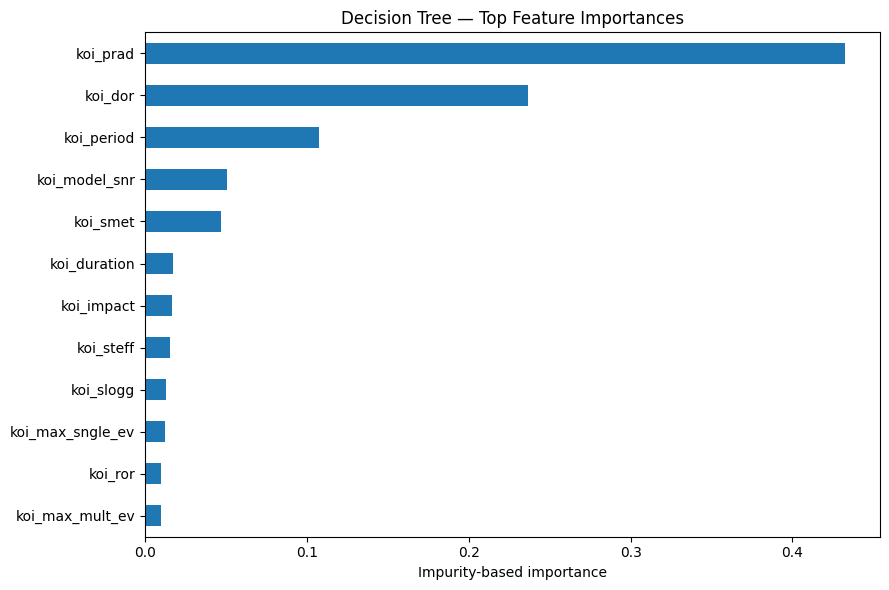

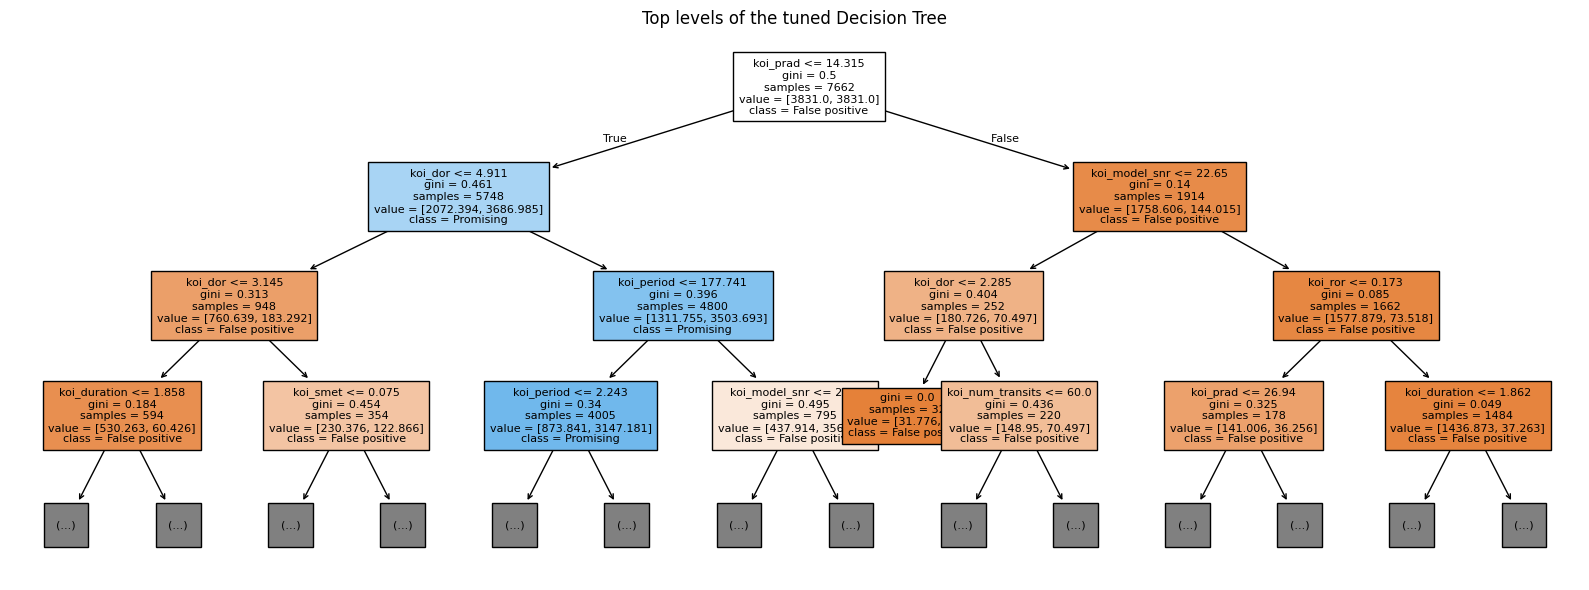

In [8]:
best_model = search.best_estimator_
tree = best_model.named_steps["tree"]
importance = pd.Series(tree.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print("Tuned tree depth:", tree.get_depth())
print("Tuned tree node count:", tree.tree_.node_count)
print("Number of terminal leaves:", tree.get_n_leaves())
print("Top feature importances:")
display(importance.head(10).to_frame("importance"))
plt.figure(figsize=(9,6))
importance.head(12).sort_values().plot.barh()
plt.title("Decision Tree — Top Feature Importances")
plt.xlabel("Impurity-based importance")
plt.tight_layout()
plt.show()
plt.figure(figsize=(16,6))
plot_tree(tree, feature_names=X_train.columns, class_names=["False positive", "Promising"],
          filled=True, max_depth=3, fontsize=8)
plt.title("Top levels of the tuned Decision Tree")
plt.tight_layout()
plt.show()

## 5. Save the model and summary
The saved pipeline includes median imputation and the tuned tree. The CSV captures validation metrics for your two-page report.

In [9]:
joblib.dump(best_model, "kepler_decision_tree_baseline.joblib")
comparison.to_csv("decision_tree_validation_scores.csv")
importance.to_csv("decision_tree_feature_importances.csv", header=["importance"])
print("Saved model and validation outputs.")

Saved model and validation outputs.


## 6. XGBoost — gradient-boosted trees (appended experiment)
This section extends the original tuned Decision Tree notebook; the previous cells are unchanged. XGBoost fits an ensemble of sequentially boosted trees rather than further training the existing single Decision Tree. We test your requested 5% learning rate, depth 5–8, L2 penalty = 1, and 1,000 trees, plus 30 boosting-round baselines, followed by a reproducible 30-trial hyperparameter search. All comparisons use five host-star-aware validation folds, optimize F1, and do not touch the held-out test set. Selection and reported cross-validation metrics share the same folds, so the selected winner may be somewhat optimistic.

In [11]:
import os, io, zipfile, time
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedGroupKFold, ParameterSampler
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, roc_auc_score

DATA_DIR = Path("Kepler_Datasets")
ZIP_FILE = Path("Kepler_Datasets(1).zip")

def xgb_load_csv(name):
    if (DATA_DIR / name).is_file():
        return pd.read_csv(DATA_DIR / name)
    if ZIP_FILE.is_file():
        with zipfile.ZipFile(ZIP_FILE) as archive:
            return pd.read_csv(io.BytesIO(archive.read(name)))
    raise FileNotFoundError(f"Cannot find {name}: expected {DATA_DIR} folder or {ZIP_FILE} archive")

xgb_X = xgb_load_csv("X_train.csv")
xgb_y = xgb_load_csv("y_train.csv")["target"].astype(int).to_numpy()
xgb_groups = xgb_load_csv("train_ids.csv")["kepid"].to_numpy()
assert len(xgb_X) == len(xgb_y) == len(xgb_groups)
assert xgb_X.shape[1] == 19
xgb_negative = int((xgb_y == 0).sum())
xgb_positive = int((xgb_y == 1).sum())
xgb_ratio = xgb_negative / xgb_positive
xgb_folds = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(xgb_X, xgb_y, xgb_groups))
print(f"Negatives: {xgb_negative}; positives: {xgb_positive}; neg/pos ratio: {xgb_ratio:.6f}")
print(f"Observations: {len(xgb_X)}; features: {xgb_X.shape[1]}; folds: {len(xgb_folds)}")

Negatives: 3858; positives: 3804; neg/pos ratio: 1.014196
Observations: 7662; features: 19; folds: 5


## 6.1 Starting settings and candidate search
The dataset is nearly balanced. scale_pos_weight = negatives / positives is 1.0142, so we compare that value with 1.0 rather than assuming class weighting is necessary. A boosting round builds one additional tree for binary classification; the 30-round experiments and 1,000-tree experiments are separate candidates. The first nine trials include the requested anchor configurations; 21 additional randomized trials explore regularization, sampling, learning rate, depth, and number of trees.

In [19]:

from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path("Kepler_Datasets")

X = pd.read_csv(DATA_DIR / "X_train.csv")

y = pd.read_csv(
    DATA_DIR / "y_train.csv"
)["target"].astype(int).to_numpy()

groups = pd.read_csv(
    DATA_DIR / "train_ids.csv"
)["kepid"].to_numpy()

assert len(X) == len(y) == len(groups)

ratio = (y == 0).sum() / (y == 1).sum()

print("Training observations:", len(X))
print("Features:", X.shape[1])
print("Negative observations:", (y == 0).sum())
print("Positive observations:", (y == 1).sum())
print("Negative-to-positive ratio:", round(ratio, 4))


Training observations: 7662
Features: 19
Negative observations: 3858
Positive observations: 3804
Negative-to-positive ratio: 1.0142


In [20]:

import time
import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    accuracy_score, roc_auc_score
)
from xgboost import XGBClassifier

ROOT = Path(".")

ratio = (y == 0).sum() / (y == 1).sum()

base = {
    "n_estimators": 600,
    "max_depth": 8,
    "learning_rate": 0.05,
    "reg_lambda": 1,
    "reg_alpha": 0,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "scale_pos_weight": 1.0
}

configs = []

def add_config(description, **changes):
    config = base.copy()
    config.update(changes)
    configs.append((description, config))

add_config("Original")

for depth in [3, 4, 5, 6]:
    add_config(f"Depth {depth}", max_depth=depth)

for child in [10, 15, 20]:
    add_config(
        f"Min child weight {child}",
        min_child_weight=child
    )

for lam in [3, 5, 10, 20, 40]:
    add_config(f"L2 {lam}", reg_lambda=lam)

for alpha in [0.1, 0.5, 1]:
    add_config(f"L1 {alpha}", reg_alpha=alpha)

add_config("300 trees", n_estimators=300)
add_config("1000 trees", n_estimators=1000)

add_config(
    "Lower learning rate",
    learning_rate=0.025,
    n_estimators=1000
)

add_config(
    "Balanced class weights",
    scale_pos_weight=ratio
)

add_config(
    "Depth 5 + L2 5 + L1 0.5 + child 15",
    max_depth=5,
    reg_lambda=5,
    reg_alpha=0.5,
    min_child_weight=15
)

folds = list(
    StratifiedGroupKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    ).split(X, y, groups)
)

results = []
fold_results = []

for trial, (description, params) in enumerate(configs, 1):

    train_scores = []
    validation_scores = []

    start = time.perf_counter()

    for fold, (tr, va) in enumerate(folds, 1):

        model = XGBClassifier(
            **params,
            objective="binary:logistic",
            eval_metric="logloss",
            tree_method="hist",
            max_bin=64,
            random_state=42,
            n_jobs=1
        )

        model.fit(X.iloc[tr], y[tr])

        train_pred = model.predict(X.iloc[tr])
        val_pred = model.predict(X.iloc[va])
        val_prob = model.predict_proba(
            X.iloc[va]
        )[:, 1]

        train_f1 = f1_score(y[tr], train_pred)
        val_f1 = f1_score(y[va], val_pred)

        train_scores.append(train_f1)
        validation_scores.append(val_f1)

        fold_results.append({
            "trial": trial,
            "description": description,
            "fold": fold,
            "train_f1": train_f1,
            "f1": val_f1,
            "precision": precision_score(
                y[va], val_pred, zero_division=0
            ),
            "recall": recall_score(
                y[va], val_pred, zero_division=0
            ),
            "accuracy": accuracy_score(
                y[va], val_pred
            ),
            "roc_auc": roc_auc_score(
                y[va], val_prob
            )
        })

    current = pd.DataFrame(
        [r for r in fold_results if r["trial"] == trial]
    )

    mean_train = current["train_f1"].mean()
    mean_val = current["f1"].mean()

    results.append({
        "trial": trial,
        "description": description,
        **params,
        "train_f1": mean_train,
        "f1": mean_val,
        "precision": current["precision"].mean(),
        "recall": current["recall"].mean(),
        "accuracy": current["accuracy"].mean(),
        "roc_auc": current["roc_auc"].mean(),
        "f1_gap": mean_train - mean_val,
        "std_f1": current["f1"].std(),
        "elapsed_seconds": time.perf_counter() - start
    })

    print(
        f"{trial}/{len(configs)} | {description} | "
        f"F1: {mean_val:.4f} | "
        f"ROC-AUC: {current['roc_auc'].mean():.4f}",
        flush=True
    )

second_pass = pd.DataFrame(results)
ranked = second_pass.sort_values(
    "f1", ascending=False
).reset_index(drop=True)

ranked.to_csv(
    ROOT / "xgboost_second_round_ranked.csv",
    index=False
)

pd.DataFrame(fold_results).to_csv(
    ROOT / "xgboost_second_round_folds.csv",
    index=False
)

columns = [
    "description", "f1", "precision", "recall",
    "accuracy", "roc_auc", "train_f1",
    "f1_gap", "std_f1"
]

print("\nBEST CONFIGURATIONS")
print(
    ranked[columns]
    .head(15)
    .round(4)
    .to_string(index=False)
)

print("\nBEST PARAMETERS")
print(ranked.iloc[0]["description"])


1/21 | Original | F1: 0.8484 | ROC-AUC: 0.9311
2/21 | Depth 3 | F1: 0.8422 | ROC-AUC: 0.9301
3/21 | Depth 4 | F1: 0.8439 | ROC-AUC: 0.9319
4/21 | Depth 5 | F1: 0.8478 | ROC-AUC: 0.9324
5/21 | Depth 6 | F1: 0.8474 | ROC-AUC: 0.9323
6/21 | Min child weight 10 | F1: 0.8490 | ROC-AUC: 0.9319
7/21 | Min child weight 15 | F1: 0.8451 | ROC-AUC: 0.9319
8/21 | Min child weight 20 | F1: 0.8471 | ROC-AUC: 0.9324
9/21 | L2 3 | F1: 0.8472 | ROC-AUC: 0.9317
10/21 | L2 5 | F1: 0.8468 | ROC-AUC: 0.9318
11/21 | L2 10 | F1: 0.8504 | ROC-AUC: 0.9331
12/21 | L2 20 | F1: 0.8494 | ROC-AUC: 0.9340
13/21 | L2 40 | F1: 0.8499 | ROC-AUC: 0.9344
14/21 | L1 0.1 | F1: 0.8473 | ROC-AUC: 0.9313
15/21 | L1 0.5 | F1: 0.8478 | ROC-AUC: 0.9315
16/21 | L1 1 | F1: 0.8474 | ROC-AUC: 0.9320
17/21 | 300 trees | F1: 0.8475 | ROC-AUC: 0.9329
18/21 | 1000 trees | F1: 0.8479 | ROC-AUC: 0.9297
19/21 | Lower learning rate | F1: 0.8484 | ROC-AUC: 0.9324
20/21 | Balanced class weights | F1: 0.8487 | ROC-AUC: 0.9320
21/21 | Depth 5 +

## 6.2 Five-fold tuning, including training and validation scores


In [13]:
xgb_rows, xgb_fold_rows = [], []
for trial, params in enumerate(xgb_candidates, 1):
    trial_folds = []
    for fold, (tr, va) in enumerate(xgb_folds, 1):
        model = XGBClassifier(
            **params, objective="binary:logistic", eval_metric="logloss",
            tree_method="hist", max_bin=64, n_jobs=2, random_state=42
        )
        start = time.perf_counter()
        model.fit(xgb_X.iloc[tr], xgb_y[tr])
        fit_seconds = time.perf_counter() - start
        predictions = model.predict(xgb_X.iloc[va])
        probabilities = model.predict_proba(xgb_X.iloc[va])[:, 1]
        train_predictions = model.predict(xgb_X.iloc[tr])
        record = dict(
            trial=trial, fold=fold,
            f1=f1_score(xgb_y[va], predictions),
            precision=precision_score(xgb_y[va], predictions, zero_division=0),
            recall=recall_score(xgb_y[va], predictions, zero_division=0),
            accuracy=accuracy_score(xgb_y[va], predictions),
            roc_auc=roc_auc_score(xgb_y[va], probabilities),
            train_f1=f1_score(xgb_y[tr], train_predictions),
            fit_seconds=fit_seconds
        )
        trial_folds.append(record)
        xgb_fold_rows.append(record)
    result = dict(trial=trial, **params)
    for metric in ["f1", "precision", "recall", "accuracy", "roc_auc", "train_f1", "fit_seconds"]:
        result["mean_" + metric] = float(np.mean([r[metric] for r in trial_folds]))
    result["std_f1"] = float(np.std([r["f1"] for r in trial_folds], ddof=1))
    xgb_rows.append(result)
    print(f"Trial {trial:02d}/30: mean val F1 = {result['mean_f1']:.4f}")

xgb_results = pd.DataFrame(xgb_rows).sort_values(["mean_f1", "std_f1"], ascending=[False, True])
xgb_fold_results = pd.DataFrame(xgb_fold_rows)
xgb_results.to_csv("kepler_xgboost_30_trial_search.csv", index=False)
xgb_fold_results.to_csv("kepler_xgboost_cv_folds.csv", index=False)
print(xgb_results.head(10).round(4).to_string(index=False))

Trial 01/30: mean val F1 = 0.8279
Trial 02/30: mean val F1 = 0.8320
Trial 03/30: mean val F1 = 0.8466
Trial 04/30: mean val F1 = 0.8492
Trial 05/30: mean val F1 = 0.8471
Trial 06/30: mean val F1 = 0.8474
Trial 07/30: mean val F1 = 0.8476
Trial 08/30: mean val F1 = 0.8494
Trial 09/30: mean val F1 = 0.8480
Trial 10/30: mean val F1 = 0.8493
Trial 11/30: mean val F1 = 0.8467
Trial 12/30: mean val F1 = 0.8444
Trial 13/30: mean val F1 = 0.8470
Trial 14/30: mean val F1 = 0.8465
Trial 15/30: mean val F1 = 0.8501
Trial 16/30: mean val F1 = 0.8474
Trial 17/30: mean val F1 = 0.8397
Trial 18/30: mean val F1 = 0.8481
Trial 19/30: mean val F1 = 0.8436
Trial 20/30: mean val F1 = 0.8493
Trial 21/30: mean val F1 = 0.8466
Trial 22/30: mean val F1 = 0.8443
Trial 23/30: mean val F1 = 0.8456
Trial 24/30: mean val F1 = 0.8508
Trial 25/30: mean val F1 = 0.8449
Trial 26/30: mean val F1 = 0.8464
Trial 27/30: mean val F1 = 0.8462
Trial 28/30: mean val F1 = 0.8483
Trial 29/30: mean val F1 = 0.8438
Trial 30/30: m

## 6.3 Winning model and comparison with the classical baseline


In [14]:
xgb_best = xgb_results.iloc[0]
xgb_keys = list(xgb_search_space.keys())
xgb_best_params = {
    key: (int(xgb_best[key]) if key in ["n_estimators", "max_depth", "min_child_weight"]
          else float(xgb_best[key]))
    for key in xgb_keys
}
xgb_metrics = pd.DataFrame({
    "metric": ["F1", "Precision", "Recall", "Accuracy", "ROC-AUC", "Training F1"],
    "XGBoost 5-fold mean": [
        xgb_best["mean_f1"], xgb_best["mean_precision"],
        xgb_best["mean_recall"], xgb_best["mean_accuracy"],
        xgb_best["mean_roc_auc"], xgb_best["mean_train_f1"]
    ]
})
print("Best configuration:", xgb_best_params)
print(xgb_metrics.round(4).to_string(index=False))
print("XGBoost F1 improvement over tuned tree:", round(float(xgb_best["mean_f1"]) - 0.8154, 4))

Best configuration: {'n_estimators': 150, 'max_depth': 7, 'learning_rate': 0.075, 'reg_lambda': 1.0, 'min_child_weight': 1, 'subsample': 1.0, 'colsample_bytree': 1.0, 'scale_pos_weight': 1.0141955835962144}
     metric  XGBoost 5-fold mean
         F1               0.8508
  Precision               0.8504
     Recall               0.8515
   Accuracy               0.8517
    ROC-AUC               0.9311
Training F1               0.9704
XGBoost F1 improvement over tuned tree: 0.0354


## 6.4 Train final selected XGBoost on all training observations
The final model is refitted on the full training partition, saved as a .joblib file, and remains unevaluated on the independent test data. The winning trial was selected using the same validation folds

In [15]:
xgb_final = XGBClassifier(
    **xgb_best_params, objective="binary:logistic", eval_metric="logloss",
    tree_method="hist", max_bin=64, n_jobs=2, random_state=42
)
xgb_final.fit(xgb_X, xgb_y)
joblib.dump(xgb_final, "kepler_xgboost_tuned.joblib")
print("Saved kepler_xgboost_tuned.joblib")

Saved kepler_xgboost_tuned.joblib


## Additional XGBoost regularization experiments (second pass)
Twenty-two configurations completed with the same five-fold StratifiedGroupKFold validation, random seed 42. F1 was the selection metric. These folds have already been used for tuning, so reported values are model-selection scores, not unbiased final test results.

In [21]:
from pathlib import Path
import pandas as pd
results_path = Path('xgboost_second_round_ranked.csv')
second_pass = pd.read_csv(results_path)
ranked = second_pass.sort_values('f1', ascending=False)
print(ranked[['description','f1','precision','recall','accuracy','roc_auc','train_f1','f1_gap','std_f1']].head(15).round(4).to_string(index=False))

           description     f1  precision  recall  accuracy  roc_auc  train_f1  f1_gap  std_f1
                 L2 10 0.8504     0.8529  0.8483    0.8519   0.9331    0.9808  0.1304  0.0075
                 L2 40 0.8499     0.8544  0.8457    0.8517   0.9344    0.9485  0.0986  0.0091
                 L2 20 0.8494     0.8525  0.8467    0.8510   0.9340    0.9684  0.1189  0.0072
   Min child weight 10 0.8490     0.8547  0.8436    0.8510   0.9319    0.9776  0.1287  0.0078
Balanced class weights 0.8487     0.8472  0.8504    0.8494   0.9320    0.9926  0.1439  0.0098
              Original 0.8484     0.8495  0.8478    0.8496   0.9311    0.9924  0.1440  0.0112
   Lower learning rate 0.8484     0.8488  0.8483    0.8495   0.9324    0.9891  0.1407  0.0056
            1000 trees 0.8479     0.8483  0.8478    0.8490   0.9297    0.9951  0.1472  0.0099
                L1 0.5 0.8478     0.8490  0.8470    0.8490   0.9315    0.9916  0.1438  0.0057
               Depth 5 0.8478     0.8504  0.8454    0.8493  

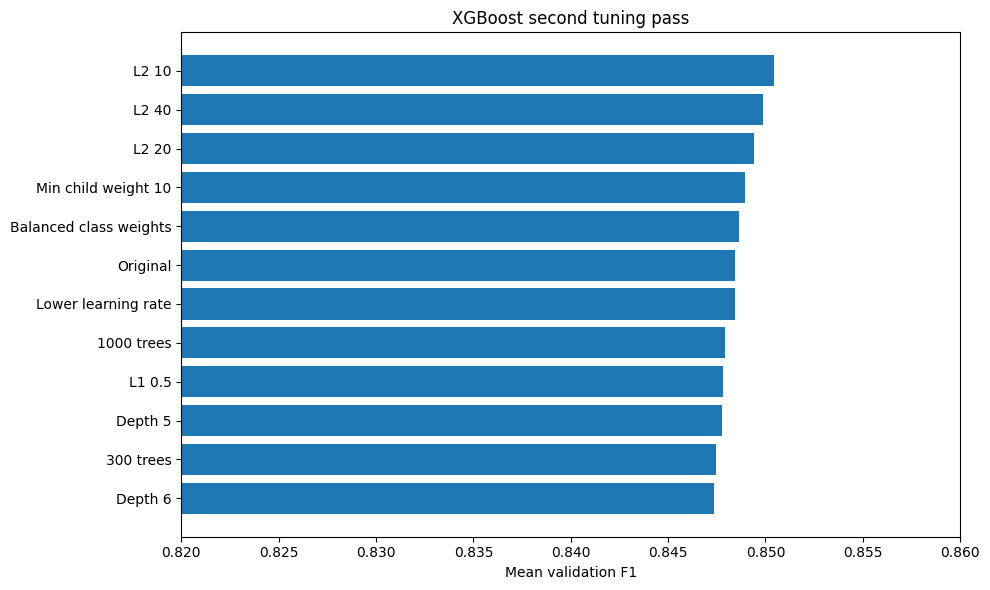

In [22]:
import matplotlib.pyplot as plt
best = second_pass.nlargest(12, 'f1').sort_values('f1')
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(best['description'], best['f1'])
ax.set_xlim(.82, .86)
ax.set_xlabel('Mean validation F1')
ax.set_title('XGBoost second tuning pass')
plt.tight_layout()
plt.show()